# Proyecto I: Clasificación y Regresión Lineal

**Contenido:**

- Ejercicio 3: Regresión lineal

## Ejercicio 3 — Regresión Lineal: Datos Artificiales

Cargaremos `Regression_Housing_Synthetic.csv`, haremos análisis descriptivo, ajuste con regresión lineal, evaluación (R², MSE, MAE), análisis de residuos y probaremos transformaciones polinómicas si mejora el ajuste.

Primeras filas de Regression_Housing_Synthetic.csv:


,area_m2,bedrooms,bathrooms,age_years,distance_to_city_center_km,neighborhood_quality_1_to_10,price_millions_COP
0,201.4,5,5,28,17.0,4,680.7
1,129.4,4,4,4,24.0,9,514.9
2,219.6,3,3,30,9.6,1,680.9
3,184.9,5,5,4,10.9,5,724.2
4,55.2,1,1,2,20.4,9,268.1



Descripción estadística:


,area_m2,bedrooms,bathrooms,age_years,distance_to_city_center_km,neighborhood_quality_1_to_10,price_millions_COP
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,141.569400,3.044000,3.078000,20.640000,13.055400,5.280000,500.671600
std,61.657757,1.407845,1.442247,12.066051,7.043713,2.849182,187.521945
min,36.200000,1.000000,1.000000,0.000000,0.500000,1.000000,73.600000
25%,85.750000,2.000000,2.000000,10.000000,6.675000,3.000000,341.150000
50%,142.700000,3.000000,3.000000,20.500000,12.750000,5.000000,509.800000
75%,195.700000,4.000000,4.000000,32.000000,19.200000,8.000000,649.825000
max,249.800000,5.000000,5.000000,40.000000,25.000000,10.000000,956.500000


Regresión lineal multivariable - métricas en test:
MSE=1682.6618, MAE=32.6903, R2=0.9429

Polinomio grado 2 - métricas en test:
MSE=1733.9754, R2=0.9412

Mejor modelo seleccionado: linear


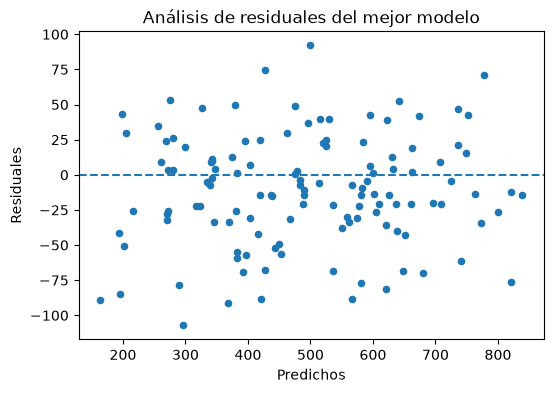

,feature,coef
2,bathrooms,16.572324
1,bedrooms,12.968205
5,neighborhood_quality_1_to_10,9.077784
0,area_m2,2.837321
4,distance_to_city_center_km,-1.707106
3,age_years,-1.464558


In [16]:

# Ejercicio 3: regresión con Regression_Housing_Synthetic.csv
import pandas as pd, numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
import matplotlib.pyplot as plt
import os

csv_path = '/Users/llara/Documents/IA/Proyecto 1/Regression_Housing_Synthetic.csv'
if not os.path.exists(csv_path):
    raise FileNotFoundError(f"No se encuentra el archivo {csv_path} en /mnt/data. Asegúrate que fue subido.")

df = pd.read_csv(csv_path)
print("Primeras filas de Regression_Housing_Synthetic.csv:")
display(df.head())

print("\nDescripción estadística:")
display(df.describe())

# Interpretación rápida: si hay una sola variable independiente y una dependiente, lo graficamos
# Decidimos identificar la variable objetivo como la última columna
cols = df.columns.tolist()
X = df[cols[:-1]].values
y = df[cols[-1]].values

# Si solo hay 1 feature, hacemos una gráfica simple con línea de regresión.
if X.shape[1] == 1:
    Xr = X.reshape(-1,1)
    X_train, X_test, y_train, y_test = train_test_split(Xr, y, test_size=0.25, random_state=0)
    lr = LinearRegression()
    lr.fit(X_train, y_train)
    y_pred = lr.predict(X_test)
    print("Coeficientes:", lr.coef_, "Intercept:", lr.intercept_)
    print("MSE:", mean_squared_error(y_test, y_pred), "MAE:", mean_absolute_error(y_test, y_pred), "R2:", r2_score(y_test, y_pred))
    # scatter + line
    xs = np.linspace(Xr.min(), Xr.max(), 200).reshape(-1,1)
    ys_line = lr.predict(xs)
    plt.figure(figsize=(6,4))
    plt.scatter(Xr, y, s=20)
    plt.plot(xs, ys_line)
    plt.title("Regresión lineal simple: datos y línea ajustada")
    plt.xlabel(cols[0]); plt.ylabel(cols[-1])
    plt.show()
else:
    # Multivariable: usaremos regresión lineal y también polinomio grado 2 si mejora
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
    lr = LinearRegression()
    lr.fit(X_train, y_train)
    y_pred = lr.predict(X_test)
    mse_lin = mean_squared_error(y_test, y_pred)
    mae_lin = mean_absolute_error(y_test, y_pred)
    r2_lin = r2_score(y_test, y_pred)
    print("Regresión lineal multivariable - métricas en test:")
    print(f"MSE={mse_lin:.4f}, MAE={mae_lin:.4f}, R2={r2_lin:.4f}")
    
    # Probar polinomio grado 2
    poly = PolynomialFeatures(degree=2, include_bias=False)
    Xp_train = poly.fit_transform(X_train)
    Xp_test = poly.transform(X_test)
    lr2 = LinearRegression()
    lr2.fit(Xp_train, y_train)
    y_pred2 = lr2.predict(Xp_test)
    mse_poly = mean_squared_error(y_test, y_pred2)
    r2_poly = r2_score(y_test, y_pred2)
    print("\nPolinomio grado 2 - métricas en test:")
    print(f"MSE={mse_poly:.4f}, R2={r2_poly:.4f}")
    
    # Elegimos el mejor modelo y mostramos análisis de residuos
    if r2_poly > r2_lin:
        best = ('polynomial_deg2', lr2, Xp_test, y_pred2)
    else:
        best = ('linear', lr, X_test, y_pred)
    name, model, Xb, ypredb = best
    print(f"\nMejor modelo seleccionado: {name}")
    residuals = y_test - ypredb
    plt.figure(figsize=(6,4))
    plt.scatter(ypredb, residuals, s=20)
    plt.axhline(0, linestyle='--')
    plt.xlabel("Predichos"); plt.ylabel("Residuales")
    plt.title("Análisis de residuales del mejor modelo")
    plt.show()
    
    # Mostrar importancia de coeficientes (si modelo lineal simple directo)
    if name == 'linear':
        coefs = lr.coef_
        coef_df = pd.DataFrame({'feature': cols[:-1], 'coef': coefs})
        display(coef_df.sort_values('coef', key=lambda x: abs(x), ascending=False))
    else:
        # para polinomio mostramos los primeros coeficientes junto con feature names
        feature_names = poly.get_feature_names_out(cols[:-1])
        coef_df = pd.DataFrame({'feature': feature_names, 'coef': lr2.coef_})
        display(coef_df.sort_values('coef', key=lambda x: abs(x), ascending=False).head(20))


## Conclusiones

- Se implementaron los tres ejercicios solicitados y se incluyeron visualizaciones y métricas de evaluación.
- En el ejercicio 2, si no fue posible descargar MNIST, se usó `digits` como sustituto para mantener la demostración y los métodos requeridos.